# Assignment Module 2: Pet Classification

The goal of this assignment is to implement a neural network that classifies images of 37 breeds of cats and dogs from the [Oxford-IIIT-Pet dataset](https://www.robots.ox.ac.uk/~vgg/data/pets/). The assignment is divided into two parts: first, you will be asked to implement from scratch your own neural network for image classification; then, you will fine-tune a pretrained network provided by PyTorch.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


IMPORT

In [ ]:
from torch.nn.functional import cross_entropy
from torch.optim import AdamW
from tqdm import tqdm
from torch.optim.lr_scheduler import OneCycleLR
from torchvision import transforms
from torch import nn, Tensor
from torch.nn import Module, Conv2d, BatchNorm2d, AdaptiveAvgPool2d, Linear, LeakyReLU, MaxPool2d

import random
import numpy as np
import torch
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from torch import Tensor
from torch.utils.data import Dataset
from typing import List, Tuple

from torch.utils.data import DataLoader

import os

## Dataset

The following cells contain the code to download and access the dataset you will be using in this assignment. Note that, although this dataset features each and every image from [Oxford-IIIT-Pet](https://www.robots.ox.ac.uk/~vgg/data/pets/), it uses a different train-val-test split than the original authors.

In [2]:
def fix_random(seed: int) -> None:
    """Fix all the possible sources of randomness.

    Args:
        seed: the seed to use.
    """
    np.random.seed(seed)
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)

    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True

fix_random(seed=115)

In [ ]:
# !git clone https://github.com/CVLAB-Unibo/ipcv-assignment-2.git

In [2]:
os.chdir("/content/drive/MyDrive/assignment_2/dataset")
os.getcwd()

'/content/drive/MyDrive/assignment_2/dataset'

In [4]:
class OxfordPetDataset(Dataset):
    def __init__(self, split: str, transform=None) -> None:
        super().__init__()

        self.root = Path("ipcv-assignment-2") / "dataset"
        self.split = split
        self.names, self.labels = self._get_names_and_labels()
        self.transform = transform

    def __len__(self) -> int:
        return len(self.labels)

    def __getitem__(self, idx) -> Tuple[Tensor, int]:
        img_path = self.root / "images" / f"{self.names[idx]}.jpg"
        img = Image.open(img_path).convert("RGB")
        label = self.labels[idx]

        if self.transform:
            img = self.transform(img)

        return img, label

    def get_num_classes(self) -> int:
        return max(self.labels) + 1

    def _get_names_and_labels(self) -> Tuple[List[str], List[int]]:
        names = []
        labels = []

        with open(self.root / "annotations" / f"{self.split}.txt") as f:
            for line in f:
                name, label = line.replace("\n", "").split(" ")
                names.append(name),
                labels.append(int(label) - 1)

        return names, labels

## Part 1: design your own network

Your goal is to implement a convolutional neural network for image classification and train it from scratch on `OxfordPetDataset`. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~60%. You are free to achieve this however you want, except for a few rules you must follow:

- Compile this notebook by displaying the results obtained by the best model you found throughout your experimentation; then show how, by removing some of its components, its performance drops. In other words, do an *ablation study* to prove that your design choices have a positive impact on the final result.

- Do not instantiate an off-the-self PyTorch network. Instead, construct your network as a composition of existing PyTorch layers. In more concrete terms, you can use e.g. `torch.nn.Linear`, but you cannot use e.g. `torchvision.models.alexnet`.

- Show your results and ablations with plots, tables, images, etc. — the clearer, the better.

Don't be too concerned with your model performance: the ~60% is just to give you an idea of when to stop. Keep in mind that a thoroughly justified model with lower accuracy will be rewarded more points than a poorly experimentally validated model with higher accuracy.

In [5]:
def get_device():
    if torch.backends.mps.is_available():
        device = "mps"
    elif torch.cuda.is_available():
        device = "cuda"
    else:
        device = "cpu"
    return device

In [6]:
def save_model(model, path: str, epoch: int, best: bool = False, epoch_freq: int = 0) -> None:
    os.makedirs(path, exist_ok=True)
    if best:
        print(f"Saving best model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, "best_model.pt"))
    else:
        print(f"Saving last model to {path}")
        torch.save(model.state_dict(), os.path.join(path, "last_model.pt"))

    if epoch_freq > 0 and epoch % epoch_freq == 0:
        print(f"Saving model at epoch {epoch} to {path}")
        torch.save(model.state_dict(), os.path.join(path, f"epoch_{epoch}.pt"))


# Hyperparameters

In [ ]:
cfg = {
    "model_name": "try_add_block_MAX_POOLING",

    #Saving parameters
    "save_freq": 15,
    "save_best": True,


    # Pre-processing's parameters.
    "train_size": 224,
    "mean": [0.485, 0.456, 0.406],
    "std": [0.229, 0.224, 0.225],

    "test_size": 256,
    "crop_size": 224,

    # Training's parameters.
    "batch_size": 32,
    "num_epochs": 130,
    "base_channels": 32,

    # Optimizer's parameters.
    "max_lr": 1.5e-3,
    "wd": 1e-4,

}

In [40]:
def triple_conv_block(in_ch: int, out_ch: int, downsample: bool = True) -> Module:
    """
    Blocco con:
    - opzionale MaxPool2d(2)
    - 3 conv 3x3 + BN + LeakyReLU
    - skip connection (proiezione 1x1 se servono canali diversi)
    """
    class TripleConvBlock(Module):
        def __init__(self):
            super().__init__()
            self.pool = MaxPool2d(2) if downsample else nn.Identity()

            self.conv1 = Conv2d(in_ch, out_ch, 3, 1, 1, bias=False)
            self.bn1   = BatchNorm2d(out_ch)
            self.act1  = LeakyReLU(negative_slope=0.1, inplace=True)

            self.conv2 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False)
            self.bn2   = BatchNorm2d(out_ch)
            self.act2  = LeakyReLU(negative_slope=0.1, inplace=True)

            self.conv3 = Conv2d(out_ch, out_ch, 3, 1, 1, bias=False) #if not downsample else Conv2d(in_ch, out_ch, 3, 2, 1, bias=False)
            self.bn3   = BatchNorm2d(out_ch)

            # ramo skip: serve se downsample o cambio canali
            self.need_skip = downsample or (in_ch != out_ch)
            if self.need_skip:
                self.skip_proj = nn.Sequential(
                    MaxPool2d(2) if downsample else nn.Identity(),
                    Conv2d(in_ch, out_ch, kernel_size=1, bias=False),
                    BatchNorm2d(out_ch)
                )
            else:
                self.skip_proj = nn.Identity()

            self.out_act = LeakyReLU(negative_slope=0.1, inplace=True)

        def forward(self, x: Tensor) -> Tensor:
            identity = x if not self.need_skip else self.skip_proj(x)

            out = self.act1(self.bn1(self.conv1(x)))
            out = self.act2(self.bn2(self.conv2(out)))
            out = self.bn3(self.conv3(out))
            out = self.pool(out)

            out = self.out_act(out + identity)
            return out

    return TripleConvBlock()


class TripleConvModel(Module):
    def __init__(self, num_classes: int, base_channels: int = 16) -> None:
        super().__init__()
        self.conv_block1 = triple_conv_block(3, base_channels)
        self.conv_block2 = triple_conv_block(base_channels, base_channels * 2)
        self.conv_block3 = triple_conv_block(base_channels * 2, base_channels * 4)
        self.conv_block4 = triple_conv_block(base_channels * 4, base_channels * 4, downsample=False)
        self.conv_block5 = triple_conv_block(base_channels * 4, base_channels * 4, downsample=False)

        self.gap = AdaptiveAvgPool2d(1)
        self.fc1 = Linear(base_channels * 4, base_channels * 4)   #RICORDA ERA X2
        self.batch_norm = nn.BatchNorm1d(base_channels * 4)
        self.leaky_relu = LeakyReLU(negative_slope=0.1)
        self.fc2 = Linear(base_channels * 4, num_classes)

    def forward(self, x: Tensor) -> Tensor:
        x = self.conv_block1(x)
        x = self.conv_block2(x)
        x = self.conv_block3(x)
        x = self.conv_block4(x)
        x = self.conv_block5(x)
        x = self.gap(x)
        x = x.view(x.size(0), -1)
        x = self.fc1(x)
        x = self.batch_norm(x)
        x = self.leaky_relu(x)
        x = self.fc2(x)
        return x


In [41]:
image_size = 224  # Dimensione dell'immagine (128x128)


'''train_tfms = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.75, 1.0), ratio=(0.8, 1.25)),
    transforms.RandomHorizontalFlip(p=0.5),
    # transforms.RandomApply([transforms.ColorJitter(
    #    brightness=0.2, contrast=0.2, saturation=0.1, hue=0.02)], p=0.8),
    # transforms.RandomGrayscale(p=0.1),
    # transforms.RandomAffine(
    #    degrees=15, translate=(0.10, 0.10), scale=(0.9, 1.1), shear=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485,0.456,0.406], std=[0.229,0.224,0.225]),
    transforms.RandomErasing(p=0.25, scale=(0.02, 0.12), ratio=(0.3, 3.3))
])'''


train_tfms = transforms.Compose([
    transforms.Resize((cfg["train_size"], cfg["train_size"])),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(mean=cfg["mean"], std=cfg["std"]),
])

# Val/Test: niente augmentation pesante
test_tfms = transforms.Compose([
    transforms.Resize(cfg["test_size"]),
    transforms.CenterCrop(cfg["crop_size"]),
    transforms.ToTensor(),
    transforms.Normalize(mean=cfg["mean"], std=cfg["std"])
])


train = OxfordPetDataset(split="train", transform=train_tfms)
validation = OxfordPetDataset(split="val", transform=test_tfms)
test = OxfordPetDataset(split="test", transform=test_tfms)
print(f"Train set: {len(train)} images, {train.get_num_classes()} classes")
print(f"Validation set: {len(validation)} images, {validation.get_num_classes()} classes")
print(f"Test set: {len(test)} images, {test.get_num_classes()} classes")

Train set: 3669 images, 37 classes
Validation set: 1834 images, 37 classes
Test set: 1846 images, 37 classes


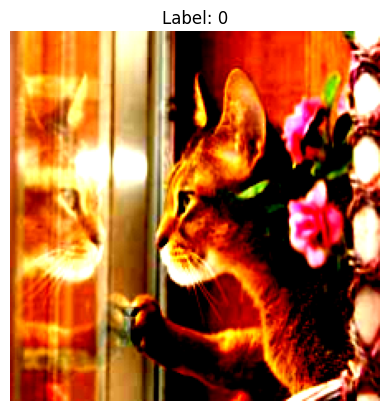

In [42]:
batch_size = cfg["batch_size"]

nw = max(2, os.cpu_count() * 3 // 4)

# Load some images
train_loader = DataLoader(train, batch_size=batch_size, shuffle=True, num_workers=nw)
validation_loader = DataLoader(validation, batch_size=batch_size, shuffle=False, num_workers=nw)
test_loader = DataLoader(test, batch_size=batch_size, shuffle=False, num_workers=nw)


# Visualize image
plt.imshow(np.transpose(train[15][0].numpy(), (1, 2, 0)))
plt.title(f"Label: {train[0][1]}")
plt.axis('off')
plt.show()


In [38]:
mean = 0.
std = 0.
total_images_count = 0

for images, _ in train_loader:
    batch_samples = images.size(0)
    images = images.view(batch_samples, images.size(1), -1)  # (B, C, H*W)
    mean += images.mean(2).sum(0)
    std += images.std(2).sum(0)
    total_images_count += batch_samples

mean /= total_images_count
std /= total_images_count

print(f"Mean: {mean.tolist()}")
print(f"Std: {std.tolist()}")

Mean: [0.48447394371032715, 0.45291826128959656, 0.39585861563682556]
Std: [0.22616341710090637, 0.2236108034849167, 0.22575609385967255]


DROPOUT

DATA AUGMENTATION

AUMENTO BASE CHANNEL DIMINUENDO IMAGE SIZE

AGGIUNGERE BLOCCO CONVOLUZIONALE

In [43]:
num_classes = train.get_num_classes()
epochs = 130
base_channels = 32
model_name = "try_add_block_MAX_POOLING"
save_freq = 15
save_best = True

device = get_device()
print(f"Using device: {device}")


model = TripleConvModel(num_classes, base_channels).to(device)
total_params = sum(p.numel() for p in model.parameters())
print(f"Numero totale di parametri: {total_params}")

criterion = cross_entropy
optimizer = AdamW(model.parameters(), weight_decay=1e-4)
lr_scheduler = OneCycleLR(optimizer, max_lr=0.0015, steps_per_epoch=len(train_loader), epochs=epochs)

losses = []
val_losses = []
val_accuracies = []
for epoch in range(epochs):
    model.train()
    epoch_loss = 0.0

    for imgs, labels in tqdm(train_loader):

        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model(imgs)

        # compute gradients
        loss = criterion(preds, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        lr_scheduler.step()


        epoch_loss += loss.item()

    epoch_loss /= len(train_loader)
    losses.append(epoch_loss)
    print(f"Epoch {epoch + 1}/{epochs}, Loss: {epoch_loss:.6f}")

    save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=False,epoch_freq=save_freq)

    # Validation
    model.eval()
    val_loss = 0.0
    total = 0
    correct = 0
    with torch.no_grad():
        for imgs, labels in validation_loader:
            imgs = imgs.to(device)
            labels = labels.to(device)

            preds = model(imgs)
            loss = criterion(preds, labels)
            val_loss += loss.item()


            _, predicted = torch.max(preds, dim=1)       # prendo la classe con probabilità più alta
            correct += (predicted == labels).sum().item()
            total += labels.size(0)

    val_loss /= len(validation_loader)
    val_losses.append(val_loss)
    print(f"Validation Loss: {val_loss:.6f}")


    val_accuracy = correct / total
    val_accuracies.append(val_accuracy)
    print(f"Validation Accuracy: {val_accuracy:.6f}")

    if save_best and val_loss <= min(val_losses, default=float('inf')):
        save_model(model, f"./checkpoints/{model_name}", epoch=epoch, best=True, epoch_freq=0)


Using device: cuda
Numero totale di parametri: 1400037


100%|██████████| 115/115 [00:19<00:00,  5.82it/s]


Epoch 1/130, Loss: 3.531659
Saving last model to ./checkpoints/try_add_block_MAX_POOLING
Saving model at epoch 0 to ./checkpoints/try_add_block_MAX_POOLING
Validation Loss: 3.472619
Validation Accuracy: 0.075791
Saving best model at epoch 0 to ./checkpoints/try_add_block_MAX_POOLING


100%|██████████| 115/115 [00:19<00:00,  5.94it/s]

Epoch 2/130, Loss: 3.365286
Saving last model to ./checkpoints/try_add_block_MAX_POOLING


Validation Loss: 3.385671
Validation Accuracy: 0.093784
Saving best model at epoch 1 to ./checkpoints/try_add_block_MAX_POOLING


... (370 outputs left out)

Epoch 129/130, Loss: 0.000733
Saving last model to ./checkpoints/try_add_block_MAX_POOLING
Validation Loss: 2.057871
Validation Accuracy: 0.609597


100%|██████████| 115/115 [00:19<00:00,  5.99it/s]

Epoch 130/130, Loss: 0.000827
Saving last model to ./checkpoints/try_add_block_MAX_POOLING


Validation Loss: 2.037621
Validation Accuracy: 0.610687


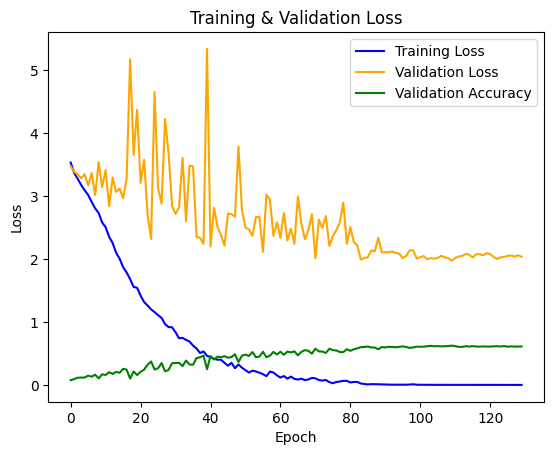

In [44]:
plt.plot(range(len(losses)), losses, label='Training Loss', color='blue')
plt.plot(range(len(val_losses)), val_losses, label='Validation Loss', color='orange')
plt.plot(range(len(val_accuracies)), val_accuracies, label='Validation Accuracy', color='green')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.show()

BEST MODEL: TRY_ADD_BLOCK, IMAGE_SIZE=224, BASE_CHANNEL=32, DATA_AUGMENTATION=only horizontal clip 0.5,

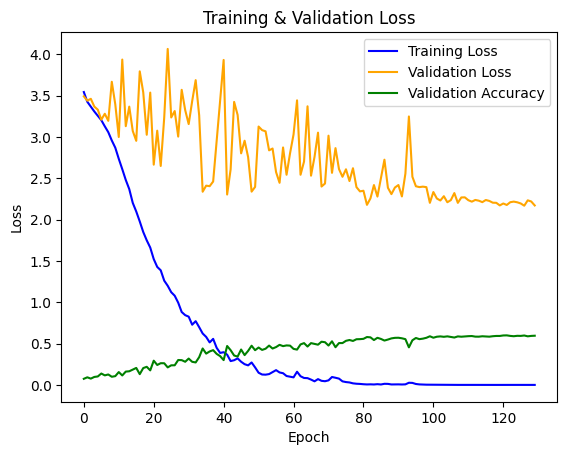

In [35]:
plt.plot(range(len(losses)), losses, label='Training Loss', color='blue')
plt.plot(range(len(val_losses)), val_losses, label='Validation Loss', color='orange')
plt.plot(range(len(val_accuracies)), val_accuracies, label='Validation Accuracy', color='green')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training & Validation Loss')
plt.legend()
plt.show()

In [47]:
model_name = "try_add_block_MAX_POOLING"
num_classes = 37
base_channels = 32
device = get_device()
print(f"Using device: {device}")
model_best = TripleConvModel(num_classes, base_channels).to(device)
model_best.load_state_dict(torch.load(f"./checkpoints/{model_name}/best_model.pt"))

model_best.eval()
correct = 0
total = 0
with torch.no_grad():
    for imgs, labels in tqdm(test_loader):
        imgs = imgs.to(device)
        labels = labels.to(device)

        preds = model_best(imgs)
        _, predicted = torch.max(preds, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()
accuracy = correct / total
print(f"Test Accuracy: {accuracy:.4f}")

Using device: cuda


100%|██████████| 58/58 [00:03<00:00, 15.38it/s]

Test Accuracy: 0.6690


## Part 2: fine-tune an existing network

Your goal is to fine-tune a pretrained ResNet-18 model on `OxfordPetDataset`. Use the implementation provided by PyTorch, i.e. the opposite of part 1. Specifically, use the PyTorch ResNet-18 model pretrained on ImageNet-1K (V1). Divide your fine-tuning into two parts:

2A. First, fine-tune the ResNet-18 with the same training hyperparameters you used for your best model in part 1.

2B. Then, tweak the training hyperparameters in order to increase the accuracy on the test split. Justify your choices by analyzing the training plots and/or citing sources that guided you in your decisions — papers, blog posts, YouTube videos, or whatever else you may find useful. You should consider yourselves satisfied once you obtain a classification accuracy on the test split of ~90%.